# 02 - Features, Viterbi and weight learning
**Project:** HMM map matching, Seattle data (UE24CS352A mini-project) | **Owner:** Person B (model side)

This notebook takes Person A's four Seattle files and does the model side of the project:

1. build the 5 features from the CS229 paper (3 emission + 2 transition)
2. decode the most likely road sequence with the **Viterbi** algorithm (whole trace, then the real-time sliding window with a buffer)
3. **learn the feature weights** with the paper's L1 SVM (the **baseline**)
4. our **two changes**: **A** = logistic regression instead of the SVM, **B** = hyperbolic secant instead of the Gaussian distance feature
5. a 2x2 results table, the delay-vs-accuracy plot, and a demo map

**How to use:** run the cells top to bottom (Runtime > Run all). The training section takes a few minutes.
Code for the three `src/` files is written by `%%writefile` cells, so after running them you can download the files and upload them to GitHub (last cell).

**Needs:** `gps.pkl`, `roads.pkl`, `candidates.pkl`, `truth_per_point.pkl` from Person A in the Drive folder `hmm-map-data`.

## 0. Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q pyproj folium "shapely>=2.0"

DATA = '/content/drive/MyDrive/hmm-map-data'      # Person A's four files live here
RESULTS = f'{DATA}/results'                       # tables and plots are saved here
!mkdir -p src {RESULTS}
!ls {DATA}

Mounted at /content/drive
02_model_and_experiments.ipynb	gps.pkl			road_network.txt
candidates.pkl			ground_truth_route.txt	roads.pkl
gps_data.txt			results			truth_per_point.pkl


## 1. Load Person A's files

In [2]:
import numpy as np, pandas as pd

gps   = pd.read_pickle(f'{DATA}/gps.pkl').reset_index(drop=True)
roads = pd.read_pickle(f'{DATA}/roads.pkl').reset_index(drop=True)
cands = pd.read_pickle(f'{DATA}/candidates.pkl')
tp    = pd.read_pickle(f'{DATA}/truth_per_point.pkl').reset_index(drop=True)

print('GPS points:', len(gps), '| roads:', len(roads), '| candidate rows:', len(cands), '| truth rows:', len(tp))
print('expected from Person A: 7531, 23456, 33579, 7531')
assert len(gps) == len(tp), 'gps and truth_per_point must have one row per GPS point'
print('gps columns  :', gps.columns.tolist())
print('roads columns:', roads.columns.tolist())
display(tp.head())

GPS points: 7531 | roads: 23456 | candidate rows: 33579 | truth rows: 7531
expected from Person A: 7531, 23456, 33579, 7531
gps columns  : ['date', 'time', 'lat', 'lon', 'timestamp', 't', 'x', 'y']
roads columns: ['edge_id', 'from_node', 'to_node', 'two_way', 'speed', 'vertex_count', 'geometry']


,pt_idx,true_edge,dist_to_true
0,0,884147800801,5.112974
1,1,884147800801,3.254902
2,2,884147800801,3.254902
3,3,884147800801,1.402133
4,4,884147800801,0.449515


**What correct looks like:** the four numbers match Person A's handoff message (7531, 23456, 33579, 7531).
If they differ, ask Person A which files are final before going on.

## 2. Settings
- `SPLIT` - the first 70% of the drive is used for **training**, the last 30% for **testing**. The Seattle data is one long drive, so we split by position along the drive and never shuffle (neighbouring GPS points are almost identical, so a random split would leak the answer).
- `MODE` - how transition feature 2 measures the distance between two roads. `'midpoint'` is exactly what the paper does. `'projection'` is an optional variant (see section 5).
- `HIST_LEN` - how many recent roads the model remembers when checking for "going back".
- `SIGMA` - the GPS noise (in metres) used by the distance feature. It is estimated from the **training part only**, using the median distance from points to their true road (the method from Newson & Krumm's paper).

In [3]:
SPLIT = 0.7
MODE = 'midpoint'        # 'midpoint' (paper) or 'projection'
HIST_LEN = 15

n = len(gps)
split = int(SPLIT * n)                         # points 0..split are training, split+1..n-1 are test
true_edge = tp['true_edge'].values
print(f'training points: 0..{split}  |  test points: {split + 1}..{n - 1}')

training points: 0..5271  |  test points: 5272..7530


## 3. The three code files
Each cell below saves one file into `src/` (that is what `%%writefile` does) and the next cell imports them.
They are the code that goes into the GitHub repo.

- **`features.py`** - turns every (GPS point, candidate road) pair into numbers. *Emission* features say "how well does this road fit this GPS dot?" (distance, direction, speed limit). *Transition* features say "does moving from road A to road B make sense?" (no going back, distance travelled matches).
- **`viterbi.py`** - the Viterbi algorithm: finds the best road sequence. Also the real-time version with window `T` and buffer `N`, and the "nearest road" baseline.
- **`train_weights.py`** - learns how much each feature matters: builds labelled examples (+1 = the true transition, -1 = everything else), trains the SVM or logistic regression, and converts its coefficients into weights.

If you edit one of these cells later, run it again and then run the import cell again.

In [4]:
%%writefile src/features.py
"""Features for HMM map matching (emission + transition), following the CS229 paper.

Everything is precomputed into flat numpy arrays (class Prep) so Viterbi stays fast.
Candidate rows come from candidates.pkl: one row per (GPS point, nearby road).
"""
import numpy as np
import pandas as pd
import shapely

MPH_40 = 17.88          # 40 mph in m/s (speed-limit feature threshold in the paper)


class Prep:
    """Flat arrays used by the matcher. 'rows' = row numbers of the (sorted) candidate table."""
    pass


def estimate_sigma(true_dist):
    """GPS noise sigma from the distance of points to their true road (Newson & Krumm's
    median-based estimate). Pass only TRAINING points to avoid leaking the test set."""
    return 1.4826 * float(np.median(true_dist))


def gauss_distance(d, sigma):
    """Emission feature 1 (paper): Gaussian of the distance to the road.
    Scaled to peak at 1 (the paper's 1/(sigma*sqrt(2*pi)) factor is dropped so that all
    features live on a 0..1 scale)."""
    return np.exp(-(d ** 2) / (2.0 * sigma ** 2))


def sech_distance(d, sigma):
    """Change B: hyperbolic-secant distance feature (heavier tails than Gaussian).
    Same scale sigma (same variance), peak 1 at d = 0."""
    return 1.0 / np.cosh(np.pi * d / (2.0 * sigma))


def heading_and_speed(gps, k=3, min_move=6.0):
    """The Seattle file has no speed/heading, so derive them from the last k seconds.
    Uses only past points (real-time safe). Returns speed (m/s), unit heading (hx, hy) and
    a 'moving' flag (heading is meaningless when the car barely moved)."""
    x, y, t = gps['x'].values, gps['y'].values, gps['t'].values
    n = len(gps)
    j = np.maximum(np.arange(n) - k, 0)
    dx, dy, dt = x - x[j], y - y[j], t - t[j]
    dist = np.hypot(dx, dy)
    speed = np.where(dt > 0, dist / np.where(dt > 0, dt, 1.0), 0.0)
    moving = dist >= min_move
    safe = np.where(dist > 0, dist, 1.0)
    return speed, dx / safe, dy / safe, moving


def prepare(gps, roads, cands, sigma, k=3, min_move=6.0):
    """Build all per-point and per-candidate arrays."""
    P = Prep()
    n = len(gps)
    P.n = n
    P.gx, P.gy, P.t = gps['x'].values, gps['y'].values, gps['t'].values
    P.speed, hx, hy, moving = heading_and_speed(gps, k, min_move)
    P.moving = moving
    P.sigma = sigma

    cands = cands.sort_values(['pt_idx', 'edge_id']).reset_index(drop=True)
    P.c_pt = cands['pt_idx'].values.astype(np.int64)
    P.c_edge = cands['edge_id'].values.astype(np.int64)
    P.c_dist = cands['dist'].values.astype(float)
    P.c_along = cands['along'].values.astype(float)
    P.c_len = cands['road_len'].values.astype(float)
    pts = np.arange(n)
    P.st = np.searchsorted(P.c_pt, pts, side='left')
    P.en = np.searchsorted(P.c_pt, pts, side='right')
    if not (P.en > P.st).all():
        bad = int((P.en <= P.st).sum())
        raise ValueError(f'{bad} GPS points have no candidate roads - increase the candidate radius')

    # map candidate rows to road table rows
    assert roads['edge_id'].is_unique, 'duplicate edge ids in roads table'
    ridx = pd.Series(np.arange(len(roads)), index=roads['edge_id'].values)
    c_ri = ridx.loc[P.c_edge].values
    geoms = roads['geometry'].values[c_ri]
    two_way = roads['two_way'].values[c_ri] == 1
    limit = roads['speed'].values[c_ri]

    # point on the road closest to the GPS point, and the road's direction there
    pp = shapely.line_interpolate_point(geoms, P.c_along)
    P.c_px, P.c_py = shapely.get_x(pp), shapely.get_y(pp)
    p0 = shapely.line_interpolate_point(geoms, np.clip(P.c_along - 1.0, 0, P.c_len))
    p1 = shapely.line_interpolate_point(geoms, np.clip(P.c_along + 1.0, 0, P.c_len))
    rdx, rdy = shapely.get_x(p1) - shapely.get_x(p0), shapely.get_y(p1) - shapely.get_y(p0)
    rn = np.hypot(rdx, rdy)
    ok = rn > 0
    rdx, rdy = rdx / np.where(ok, rn, 1.0), rdy / np.where(ok, rn, 1.0)

    # midpoints of each candidate's road (used by transition feature 2)
    mid = shapely.line_interpolate_point(geoms, 0.5, normalized=True)
    P.c_mx, P.c_my = shapely.get_x(mid), shapely.get_y(mid)

    # ---- emission features, one row per candidate ----
    f1g = gauss_distance(P.c_dist, sigma)
    f1s = sech_distance(P.c_dist, sigma)

    # feature 2: direction. |cos| for two-way roads; one-way roads only count if we go with them
    dot = hx[P.c_pt] * rdx + hy[P.c_pt] * rdy
    f2 = np.where(two_way, np.abs(dot), np.maximum(dot, 0.0))
    f2 = np.where(moving[P.c_pt] & ok, f2, 0.5)          # neutral when heading unknown

    # feature 3: speed limit. 0 if we drive >40 mph and >=20% above this road's limit
    v = P.speed[P.c_pt]
    f3 = np.where((v > MPH_40) & (v >= 1.2 * limit), 0.0, 1.0)

    P.f1_gauss, P.f1_sech, P.f2, P.f3 = f1g, f1s, f2, f3
    P.F_gauss = np.column_stack([f1g, f2, f3])      # baseline emission features
    P.F_sech = np.column_stack([f1s, f2, f3])       # change B emission features
    return P


def trans_feats(P, ra, rb, i, H, mode='midpoint'):
    """Transition features for every pair (a in ra at point i-1) -> (b in rb at point i).

    omega1 (backtrack): 0 if b was already on a's recent path (and b != a), else 1.
    omega2 (distance discrepancy): 1 / (|d(GPS_i, GPS_i-1) - d(road a, road b)| + 1).
        mode='midpoint'  : d(road a, road b) = distance between the roads' midpoints (paper)
        mode='projection': distance between the projected points (|along diff| on same road)
    H : (len(ra), L) array with the most recent road ids on each predecessor's best path
    Returns two (len(ra), len(rb)) matrices."""
    d_gps = np.hypot(P.gx[i] - P.gx[i - 1], P.gy[i] - P.gy[i - 1])
    ea, eb = P.c_edge[ra], P.c_edge[rb]
    if mode == 'midpoint':
        d_road = np.hypot(P.c_mx[ra][:, None] - P.c_mx[rb][None, :],
                          P.c_my[ra][:, None] - P.c_my[rb][None, :])
    else:
        d_proj = np.hypot(P.c_px[ra][:, None] - P.c_px[rb][None, :],
                          P.c_py[ra][:, None] - P.c_py[rb][None, :])
        same = ea[:, None] == eb[None, :]
        d_road = np.where(same, np.abs(P.c_along[rb][None, :] - P.c_along[ra][:, None]), d_proj)
    om2 = 1.0 / (np.abs(d_gps - d_road) + 1.0)
    seen = (H[:, None, :] == eb[None, :, None]).any(axis=2)
    om1 = 1.0 - (seen & (ea[:, None] != eb[None, :])).astype(float)
    return om1, om2

Writing src/features.py


In [5]:
%%writefile src/viterbi.py
"""Viterbi map matching: whole-trace, sliding window with buffer, and a nearest-road baseline."""
import numpy as np
from features import trans_feats

EPS = 1e-9


def _hist_from_edges(edges, L):
    """Right-aligned history array of length L (padded with -1)."""
    h = np.full(L, -1, dtype=np.int64)
    edges = np.asarray(edges, dtype=np.int64)[-L:]
    if len(edges):
        h[L - len(edges):] = edges
    return h


def decode_segment(P, F, i0, i1, w_em, w_tr, prev_row=None, prev_hist=None,
                   mode='midpoint', L=15):
    """Best road sequence for GPS points i0..i1 (inclusive).

    F        : (n_candidates, 3) emission features (P.F_gauss or P.F_sech)
    w_em     : 3 emission weights, w_tr : 2 transition weights (each group sums to 1)
    prev_row : candidate row already decided for point i0-1 (None = start of the trace)
    prev_hist: recent road ids on that decided path (length L)
    Returns the list of candidate rows (one per point)."""
    rows = np.arange(P.st[i0], P.en[i0])
    lem = np.log(F[rows] @ w_em + EPS)
    if prev_row is None:
        score = lem
        H = np.full((len(rows), L), -1, dtype=np.int64)
        H[:, -1] = P.c_edge[rows]
    else:
        ra = np.array([prev_row])
        Ha = prev_hist[None, :]
        om1, om2 = trans_feats(P, ra, rows, i0, Ha, mode)
        score = np.log(w_tr[0] * om1[0] + w_tr[1] * om2[0] + EPS) + lem
        H = np.concatenate([np.repeat(Ha[:, 1:], len(rows), axis=0), P.c_edge[rows][:, None]], axis=1)

    all_rows, back = [rows], []
    for i in range(i0 + 1, i1 + 1):
        rb = np.arange(P.st[i], P.en[i])
        om1, om2 = trans_feats(P, rows, rb, i, H, mode)
        lt = np.log(w_tr[0] * om1 + w_tr[1] * om2 + EPS)
        tot = score[:, None] + lt
        best_a = tot.argmax(axis=0)
        score = tot[best_a, np.arange(len(rb))] + np.log(F[rb] @ w_em + EPS)
        H = np.concatenate([H[best_a][:, 1:], P.c_edge[rb][:, None]], axis=1)
        back.append(best_a)
        all_rows.append(rb)
        rows = rb

    j = int(score.argmax())
    path = [all_rows[-1][j]]
    for k in range(len(back) - 1, -1, -1):
        j = int(back[k][j])
        path.append(all_rows[k][j])
    return path[::-1]


def sliding_decode(P, F, w_em, w_tr, T, N, i_start, i_end, mode='midpoint', L=15):
    """Real-time matching. Window = last T points; the decision for point i is made at time
    i+N (a delay of N points), so N 'future' points can correct it. Decisions never change.
    Needs N <= T-1. Returns {point index: candidate row}."""
    assert 0 <= N <= T - 1, 'buffer N must satisfy 0 <= N <= T-1'
    final = {}
    path, s = None, i_start
    for t in range(i_start, i_end + 1):
        s = max(i_start, t - T + 1)
        if s > i_start:
            prev_row = final[s - 1]
            past = [P.c_edge[final[j]] for j in range(max(i_start, s - L), s)]
            prev_hist = _hist_from_edges(past, L)
        else:
            prev_row, prev_hist = None, None
        path = decode_segment(P, F, s, t, w_em, w_tr, prev_row, prev_hist, mode, L)
        d = t - N
        if d >= i_start:
            final[d] = path[d - s]
    for d in range(max(i_start, i_end - N + 1), i_end + 1):      # flush the last N points
        final[d] = path[d - s]
    return final


def nearest_road(P, i_start, i_end):
    """Baseline with no HMM: pick the closest candidate road for every point."""
    return {i: P.st[i] + int(np.argmin(P.c_dist[P.st[i]:P.en[i]])) for i in range(i_start, i_end + 1)}


def accuracy(P, chosen, true_edge, i_start, i_end):
    """Fraction of points whose chosen road equals the true road (1 - the paper's error E)."""
    if isinstance(chosen, dict):
        pred = np.array([P.c_edge[chosen[i]] for i in range(i_start, i_end + 1)])
    else:
        pred = np.array([P.c_edge[r] for r in chosen])
    return float((pred == np.asarray(true_edge)[i_start:i_end + 1]).mean())

Writing src/viterbi.py


In [6]:
%%writefile src/train_weights.py
"""Learn the feature weights from labelled transitions (paper Section 4.3).

Every pair (road a at point i-1) -> (road b at point i) is one training example with 5 features
[emission f1, f2, f3 of b, transition omega1, omega2]. Label +1 = the true transition, -1 = all others
(only about 5-10% of examples are +1, so class weights are used)."""
import warnings
import numpy as np
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import f1_score
from features import trans_feats

warnings.filterwarnings('ignore', message='.*penalty.*')   # newer scikit-learn nags about 'penalty'

C_GRID = [0.01, 0.1, 1]        # the paper found C = 1 best


def build_pairs(P, F, true_edge, i_lo, i_hi, mode='midpoint', L=15):
    """Training examples for points i_lo..i_hi. Steps where the true road is not among the
    candidates are skipped. Returns X (n,5), y (n,) with y in {+1,-1}."""
    true_edge = np.asarray(true_edge, dtype=np.int64)
    Xs, ys = [], []
    for i in range(max(i_lo, 1), i_hi + 1):
        ra = np.arange(P.st[i - 1], P.en[i - 1])
        rb = np.arange(P.st[i], P.en[i])
        ea, eb = P.c_edge[ra], P.c_edge[rb]
        ta = np.where(ea == true_edge[i - 1])[0]
        tb = np.where(eb == true_edge[i])[0]
        if len(ta) == 0 or len(tb) == 0:
            continue
        # recent history = the TRUE path before point i-1, plus the predecessor itself
        past = true_edge[max(0, i - L):i - 1]
        base = np.full(L - 1, -1, dtype=np.int64)
        if len(past):
            base[L - 1 - len(past):] = past
        H = np.hstack([np.tile(base, (len(ra), 1)), ea[:, None]])
        om1, om2 = trans_feats(P, ra, rb, i, H, mode)
        na, nb = len(ra), len(rb)
        X = np.empty((na * nb, 5))
        X[:, :3] = np.tile(F[rb], (na, 1))
        X[:, 3] = om1.ravel()
        X[:, 4] = om2.ravel()
        y = -np.ones((na, nb))
        y[ta[0], tb[0]] = 1
        Xs.append(X)
        ys.append(y.ravel())
    return np.vstack(Xs), np.concatenate(ys)


def make_model(kind):
    """'svm' = the paper's L1 SVM (baseline); 'logreg' = change A (L1 logistic regression)."""
    if kind == 'svm':
        return LinearSVC(penalty='l1', loss='squared_hinge', dual=False,
                         class_weight='balanced', tol=1e-3, max_iter=20000)
    if kind == 'logreg':
        return LogisticRegression(penalty='l1', solver='liblinear',
                                  class_weight='balanced', tol=1e-3, max_iter=2000)
    raise ValueError(kind)


def fit_model(X, y, kind, c_grid=C_GRID, folds=5):
    """Tune C by cross-validation on contiguous blocks (no shuffling: neighbouring GPS points
    are almost identical, so shuffled folds would leak). Returns (fitted model, best C)."""
    gs = GridSearchCV(make_model(kind), {'C': list(c_grid)}, scoring='f1',
                      cv=KFold(n_splits=folds, shuffle=False))
    gs.fit(X, y)
    return gs.best_estimator_, gs.best_params_['C']


def to_weights(coef):
    """Turn model coefficients into HMM weights: drop negatives, then rescale each group
    (3 emission, 2 transition) to sum to 1, as in the paper (||w||_1 = 1)."""
    w = np.clip(np.asarray(coef, dtype=float).ravel(), 0, None)

    def norm(v):
        s = v.sum()
        return v / s if s > 0 else np.ones(len(v)) / len(v)

    return norm(w[:3]), norm(w[3:])


def classifier_f1(model, X, y):
    return float(f1_score(y, model.predict(X), pos_label=1))

Writing src/train_weights.py


In [7]:
import sys, importlib
sys.path.insert(0, 'src')
import features, viterbi, train_weights
for m in (features, viterbi, train_weights):      # reload so edits to the files take effect
    importlib.reload(m)
from features import *
from viterbi import *
from train_weights import *
print('modules loaded')

modules loaded


## 4. Build the features
`prepare` computes, for every candidate road of every GPS point: the three emission features (`F_gauss` = baseline, `F_sech` = change B) and what the transition features need.
The Seattle file has no speed or heading, so they are derived from the last 3 seconds of GPS positions.

In [8]:
SIGMA = estimate_sigma(tp['dist_to_true'].values[:split])      # training part only
print(f'GPS noise sigma estimated from training points: {SIGMA:.2f} m')

P = prepare(gps, roads, cands, SIGMA)
print('candidate rows:', len(P.c_edge), '| points:', P.n)

GPS noise sigma estimated from training points: 4.38 m
candidate rows: 33579 | points: 7531


### Sanity check of the features
For the **true** roads the features should be clearly higher than for the other candidate roads.
Direction (`f2`) is only meaningful while the car is moving, so the second line checks moving points only.

In [9]:
is_true = P.c_edge == true_edge[P.c_pt]
cols = ['f1 distance', 'f2 direction', 'f3 speed limit']
print(pd.DataFrame({'true road': P.F_gauss[is_true].mean(0),
                    'other candidates': P.F_gauss[~is_true].mean(0)}, index=cols).round(3))

mv = is_true & P.moving[P.c_pt]
print()
print('share of GPS points where the car is moving:', round(P.moving.mean(), 3))
print('mean direction feature on the true road, moving points only:', round(P.F_gauss[mv, 1].mean(), 3))

                true road  other candidates
f1 distance         0.713             0.077
f2 direction        0.847             0.505
f3 speed limit      0.961             0.884

share of GPS points where the car is moving: 0.719
mean direction feature on the true road, moving points only: 0.983


**What correct looks like:** true roads have higher `f1` and `f2` than the others, and the direction score on the true road while moving should be high (roughly above 0.8).
A much lower direction score would mean the road directions are being read wrongly - stop and ask.

## 5. Baselines without any learning
Two reference points before training anything:

- **Nearest road** - no HMM at all, just pick the closest candidate road for every GPS point.
- **Hand-picked weights** - the HMM with guessed weights (emission 0.5 / 0.3 / 0.2, transition 0.5 / 0.5).

The HMM should beat nearest-road. If it does not, something is wrong.
Accuracy = fraction of GPS points matched to the correct road (the paper's error is `E = 1 - accuracy`).

In [10]:
w_em0, w_tr0 = np.array([0.5, 0.3, 0.2]), np.array([0.5, 0.5])

acc_nearest_all  = accuracy(P, nearest_road(P, 0, n - 1), true_edge, 0, n - 1)
acc_nearest_test = accuracy(P, nearest_road(P, split + 1, n - 1), true_edge, split + 1, n - 1)

path_hand = decode_segment(P, P.F_gauss, 0, n - 1, w_em0, w_tr0, mode=MODE, L=HIST_LEN)
acc_hand_all  = accuracy(P, path_hand, true_edge, 0, n - 1)
acc_hand_test = accuracy(P, path_hand[split + 1:], true_edge, split + 1, n - 1)

print(f'nearest road        : whole drive {acc_nearest_all:.4f} | test part {acc_nearest_test:.4f}')
print(f'HMM, hand-picked w  : whole drive {acc_hand_all:.4f} | test part {acc_hand_test:.4f}')

nearest road        : whole drive 0.9140 | test part 0.9199
HMM, hand-picked w  : whole drive 0.9288 | test part 0.9504


**Optional:** if the HMM is *not* clearly better than nearest-road, try `MODE = 'projection'` in the settings cell (it measures road-to-road distance from the projected points instead of the midpoints) and re-run from section 2. Say in the write-up which one you used.

## 6. Learn the weights (baseline = paper's method)
Every pair "road *a* at the previous GPS point -> road *b* at this point" becomes one training example with 5 numbers (the 3 emission features of *b* and the 2 transition features).
The label is **+1** for the true transition and **-1** for all the others, so only about 5-10% of the examples are +1. That is why `class_weight='balanced'` is used.

- The model is an **L1-regularised linear SVM** (the paper's choice). The cost parameter **C is tuned by cross-validation** on contiguous blocks of the training drive.
- The 5 learned coefficients become the HMM weights: negatives are set to 0, then the 3 emission weights are rescaled to sum to 1 and so are the 2 transition weights (the paper's `||w||_1 = 1`).
- We then decode the **test part of the drive** with the learned weights and measure accuracy.

*Simplification vs the paper:* the paper trains the emission and transition weights separately; here one model learns all five together and we split the coefficients afterwards.

In [11]:
Xtr, ytr = build_pairs(P, P.F_gauss, true_edge, 1, split, MODE, HIST_LEN)
print('training examples:', Xtr.shape, '| share labelled +1:', round(float((ytr > 0).mean()), 3))

training examples: (123578, 5) | share labelled +1: 0.042


## 7. The 2x2 experiment: our two changes
| | Gaussian distance (paper) | Hyperbolic secant distance (**change B**) |
|---|---|---|
| **L1 SVM (paper)** | **baseline** | B only |
| **L1 logistic regression (change A)** | A only | A + B |

Everything else is identical in all four runs: same data, same split, same features, same C grid, same folds.
The paper itself suggests trying a different GPS-error distribution such as the hyperbolic secant; logistic regression gives probabilities, which suit an HMM.
*This cell takes a few minutes.*

In [12]:
import time
kinds  = [('svm', 'L1 SVM (paper)'), ('logreg', 'L1 logistic regression (change A)')]
dists  = [('gauss', P.F_gauss, 'Gaussian (paper)'), ('sech', P.F_sech, 'Hyperbolic secant (change B)')]

rows, paths, weights = [], {}, {}
for kind, kind_name in kinds:
    for dkey, F, dist_name in dists:
        t0 = time.time()
        Xtr, ytr = build_pairs(P, F, true_edge, 1, split, MODE, HIST_LEN)
        Xte, yte = build_pairs(P, F, true_edge, split + 1, n - 1, MODE, HIST_LEN)
        model, C = fit_model(Xtr, ytr, kind)
        w_em, w_tr = to_weights(model.coef_)
        path = decode_segment(P, F, split + 1, n - 1, w_em, w_tr, mode=MODE, L=HIST_LEN)
        paths[(kind, dkey)], weights[(kind, dkey)] = path, (w_em, w_tr)
        rows.append({'Model': kind_name, 'Distance feature': dist_name, 'best C': C,
                     'F1 (test pairs)': classifier_f1(model, Xte, yte),
                     'Accuracy (test drive)': accuracy(P, path, true_edge, split + 1, n - 1),
                     'emission weights': np.round(w_em, 2).tolist(),
                     'transition weights': np.round(w_tr, 2).tolist()})
        print(f"done: {kind_name} + {dist_name}  ({time.time() - t0:.0f} s)")

done: L1 SVM (paper) + Gaussian (paper)  (200 s)
done: L1 SVM (paper) + Hyperbolic secant (change B)  (160 s)
done: L1 logistic regression (change A) + Gaussian (paper)  (159 s)
done: L1 logistic regression (change A) + Hyperbolic secant (change B)  (153 s)


In [13]:
res = pd.DataFrame(rows)
res['Error E (test drive)'] = 1 - res['Accuracy (test drive)']
base_acc = res.loc[0, 'Accuracy (test drive)']           # row 0 = SVM + Gaussian = baseline
res['Change vs baseline (pct points)'] = (res['Accuracy (test drive)'] - base_acc) * 100

refs = pd.DataFrame([
    {'Model': 'Nearest road (no HMM)', 'Distance feature': '-', 'Accuracy (test drive)': acc_nearest_test},
    {'Model': 'HMM, hand-picked weights', 'Distance feature': 'Gaussian (paper)', 'Accuracy (test drive)': acc_hand_test}])
refs['Error E (test drive)'] = 1 - refs['Accuracy (test drive)']
refs['Change vs baseline (pct points)'] = (refs['Accuracy (test drive)'] - base_acc) * 100

table = pd.concat([refs, res], ignore_index=True)
display(table.round(4))
table.to_csv(f'{RESULTS}/results.csv', index=False)
print('saved results.csv')

,Model,Distance feature,Accuracy (test drive),Error E (test drive),Change vs baseline (pct points),best C,F1 (test pairs),emission weights,transition weights
0,Nearest road (no HMM),-,0.9199,0.0801,-3.0102,NaN,NaN,NaN,NaN
1,"HMM, hand-picked weights",Gaussian (paper),0.9504,0.0496,0.0443,NaN,NaN,NaN,NaN
2,L1 SVM (paper),Gaussian (paper),0.9500,0.0500,0.0000,1.0,0.4536,"[0.45, 0.42, 0.14]","[0.66, 0.34]"
3,L1 SVM (paper),Hyperbolic secant (change B),0.9504,0.0496,0.0443,1.0,0.4459,"[0.44, 0.41, 0.15]","[0.66, 0.34]"
4,L1 logistic regression (change A),Gaussian (paper),0.9495,0.0505,-0.0443,1.0,0.4551,"[0.42, 0.44, 0.14]","[0.72, 0.28]"
5,L1 logistic regression (change A),Hyperbolic secant (change B),0.9509,0.0491,0.0885,0.1,0.4481,"[0.44, 0.42, 0.14]","[0.69, 0.31]"


saved results.csv


**How to read it:** the first row of the learned models (SVM + Gaussian) is the **baseline**. "Change vs baseline" is in percentage points of accuracy on the test part of the drive.
If a change does not help, that is still a valid result - report it honestly and say why you think so.
`F1 (test pairs)` scores the weight-learning classifier itself (how well it spots the true transition); the accuracy column is what finally matters.

## 8. Delay versus accuracy (the paper's main idea)
In real time you cannot wait for the whole trip. The matcher keeps a **window of the last T points**, and the decision for a point is made **N points later** (the buffer), so N "future" points can correct it. Bigger N means more delay but usually fewer mistakes.
Here we use the **baseline weights** and plot the error on the test drive for a few window sizes `T` and buffers `N`.
The dashed line is the error when the whole test drive is decoded at once (no real-time limit).

,window T,buffer N,accuracy,error %
0,5,0,0.9261,7.3927
1,5,1,0.9416,5.8433
2,5,2,0.9425,5.7548
3,5,3,0.9425,5.7548
4,5,4,0.9429,5.7105
5,10,0,0.9265,7.3484
6,10,2,0.9425,5.7548
7,10,5,0.9429,5.7105
8,10,7,0.9429,5.7105
9,10,9,0.9429,5.7105


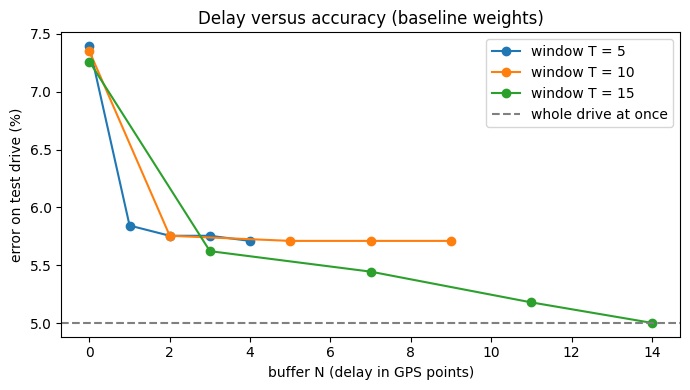

In [14]:
import matplotlib.pyplot as plt

w_em_b, w_tr_b = weights[('svm', 'gauss')]
sw_rows = []
for T in (5, 10, 15):
    for N in sorted({0, T // 4, T // 2, (3 * T) // 4, T - 1}):
        fin = sliding_decode(P, P.F_gauss, w_em_b, w_tr_b, T, N, split + 1, n - 1, MODE, HIST_LEN)
        sw_rows.append({'window T': T, 'buffer N': N,
                        'accuracy': accuracy(P, fin, true_edge, split + 1, n - 1)})
sw = pd.DataFrame(sw_rows)
sw['error %'] = (1 - sw['accuracy']) * 100
display(sw.round(4))

plt.figure(figsize=(7, 4))
for T, g in sw.groupby('window T'):
    plt.plot(g['buffer N'], g['error %'], marker='o', label=f'window T = {T}')
plt.axhline((1 - base_acc) * 100, color='gray', linestyle='--', label='whole drive at once')
plt.xlabel('buffer N (delay in GPS points)')
plt.ylabel('error on test drive (%)')
plt.title('Delay versus accuracy (baseline weights)')
plt.legend()
plt.tight_layout()
plt.savefig(f'{RESULTS}/error_vs_buffer.png', dpi=150)
plt.show()
sw.to_csv(f'{RESULTS}/error_vs_buffer.csv', index=False)

Do not expect a perfect copy of the paper's curve (different data and city). Just describe what you see: does the error fall as the buffer grows, and where does it level off?

## 9. Demo map
Shows the part of the test drive where the baseline made the most mistakes (120 consecutive points):
**grey dots** = GPS points matched correctly, **red dots** = GPS points matched to the wrong road, **blue lines** = roads the matcher chose, **green dashed lines** = the true roads.
The map is also saved as `demo_map.html` in the results folder for the live demo.

In [15]:
import folium
from pyproj import Transformer
TO_LL = Transformer.from_crs(32610, 4326, always_xy=True)

def to_latlon(geom):
    xy = np.array(geom.coords)
    lon, lat = TO_LL.transform(xy[:, 0], xy[:, 1])
    return list(zip(lat, lon))

geom_of = dict(zip(roads['edge_id'], roads['geometry']))
path_b = paths[('svm', 'gauss')]
pred = np.array([P.c_edge[r] for r in path_b])
truth_test = true_edge[split + 1:]
wrong = pred != truth_test

WIN = 120
counts = np.convolve(wrong.astype(int), np.ones(WIN, dtype=int), mode='valid')
a = int(counts.argmax())                                   # window with the most mistakes
idx = np.arange(a, a + WIN)
print(f'showing test points {split + 1 + a} to {split + a + WIN}: {int(wrong[idx].sum())} wrong out of {WIN}')

pts = split + 1 + idx
m = folium.Map(location=[gps['lat'].values[pts].mean(), gps['lon'].values[pts].mean()], zoom_start=16,
               tiles='https://tile.openstreetmap.de/{z}/{x}/{y}.png', attr='(c) OpenStreetMap contributors')
for e in sorted(set(truth_test[idx])):
    folium.PolyLine(to_latlon(geom_of[e]), color='green', weight=5, dash_array='8', opacity=0.8).add_to(m)
for e in sorted(set(pred[idx])):
    folium.PolyLine(to_latlon(geom_of[e]), color='blue', weight=3, opacity=0.8).add_to(m)
for k, i in zip(idx, pts):
    folium.CircleMarker([gps['lat'].values[i], gps['lon'].values[i]], radius=3,
                        color='red' if wrong[k] else '#555555', fill=True, fill_opacity=0.9,
                        popup=f'point {i}').add_to(m)
m.save(f'{RESULTS}/demo_map.html')
m

showing test points 7345 to 7464: 35 wrong out of 120


## 10. Save everything to GitHub
1. Run the cell below. It zips the `src/` folder and downloads it. Unzip it and upload `features.py`, `viterbi.py` and `train_weights.py` into the `src/` folder of the repo (GitHub > Add file > Upload files).
2. Tables and plots are already in the `results` folder on Drive (`results.csv`, `error_vs_buffer.png`, `error_vs_buffer.csv`, `demo_map.html`). Upload `results.csv` and the PNG to a `results/` folder in the repo.
3. Run **Runtime > Run all** once more to check the notebook works from the top, then **File > Save a copy in GitHub** as `notebooks/02_model_and_experiments.ipynb`.

In [16]:
!zip -r src_model.zip src
from google.colab import files
files.download('src_model.zip')

  adding: src/ (stored 0%)
  adding: src/__pycache__/ (stored 0%)
  adding: src/__pycache__/train_weights.cpython-313.pyc (deflated 43%)
  adding: src/__pycache__/viterbi.cpython-313.pyc (deflated 44%)
  adding: src/__pycache__/features.cpython-313.pyc (deflated 52%)
  adding: src/features.py (deflated 60%)
  adding: src/train_weights.py (deflated 53%)
  adding: src/viterbi.py (deflated 60%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>